# OHC Figures for paper

Summary figures comparing conditions side by side, using the data shown one experiment at a time in
`OHC_proc.ipynb`. Plotting functions live in `ohc_cases.py`.

**Conventions.** Data run 2035–2069. *Time series* (figures 1, 3, 5) show the change since **2035**: each member's
2035 annual mean is subtracted, so all curves start at 0. *Scatter plots* (figures 2, 2b, 4, 6) measure both
surface-temperature change and ocean heat uptake as the **2065–2069 mean minus the 2035–2039 mean** (large points);
their 10-year-window points are window means minus the same 2035–2039 mean. Annual means weight each month by its length. Ensembles are
member means. Ocean heat content is the full-column global total (ZJ = 10²¹ J); surface temperature is the
global-mean `TS` from PRISM's spatial-average files (the same data `J04_CESM_EEI_timeseries_multiensemble.py`
uses), loaded directly rather than through J04's loader, which prepends a different run's years before 2035.

In [1]:
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "/glade/work/wkamp/GEO/PRISM/PRISM/OHC_levels")
import ohc_cases as oc

plt.rcParams.update(oc.STYLE)

START, END = 2035, 2069   # all changes are relative to START's annual mean
WINDOW = 10               # years per small point in the scatter plots
BASE, FINAL = (2035, 2039), (2065, 2069)   # scatter plots: change = mean over FINAL minus mean over BASE

ARISE_CONDITIONS = {      # display name: (family, experiment)
    "SSP2-4.5": ("CESM2_WACCM_SSP2-4.5", "CMIP6-SSP2-4.5-WACCM"),
    "ARISE-1.5": ("ARISE_SAI", "SSP245-TSMLT-GAUSS-DEFAULT"),
    "ARISE-1.0": ("ARISE-1.0", "SSP245-TSMLT-GAUSS-LOWER-0.5"),
}
MCB_CONDITIONS = {
    "MCB baseline (no MCB)": ("CESM2_WACCM_SSP2-4.5_MCB", "CMIP6-baseline"),
    "MCB 25%": ("CESM2_WACCM_SSP2-4.5_MCB", "CMIP6-MCB-025PCT"),
    "MCB 50%": ("CESM2_WACCM_SSP2-4.5_MCB", "CMIP6-MCB-050PCT"),
    "MCB 75%": ("CESM2_WACCM_SSP2-4.5_MCB", "CMIP6-MCB-075PCT"),
    "MCB 125%": ("CESM2_WACCM_SSP2-4.5_MCB", "CMIP6-MCB-125PCT"),
    "MCB 50% ensemble (smbb)": ("CESM2_WACCM_SSP2-4.5_MCB", "MCB-050PCT"),
}

# One look per condition in every figure. Color identifies the condition (the two no-intervention references
# share blue); line style / marker shape identifies the model family: CESM2-WACCM (solid, circles) for SSP2-4.5
# and ARISE, CESM2 with CAM6 (dashed, squares) for the MCB runs.
WACCM, CAM6 = {"linestyle": "-", "marker": "o"}, {"linestyle": "--", "marker": "s"}
CONDITION_STYLES = {
    "SSP2-4.5": {"color": oc.PALETTE[0], **WACCM},
    "ARISE-1.5": {"color": oc.PALETTE[1], **WACCM},
    "ARISE-1.0": {"color": oc.PALETTE[2], **WACCM},
    "MCB baseline (no MCB)": {"color": oc.PALETTE[0], **CAM6},
    "MCB 25%": {"color": oc.PALETTE[3], **CAM6},
    "MCB 50%": {"color": oc.PALETTE[4], **CAM6},
    "MCB 75%": {"color": oc.PALETTE[5], **CAM6},
    "MCB 125%": {"color": oc.PALETTE[6], **CAM6},
    "MCB 50% ensemble (smbb)": {"color": oc.PALETTE[7], **CAM6},
}
FAMILY_MARKERS = {"CESM2-WACCM (SSP2-4.5, ARISE)": "o", "CESM2 with CAM6 (MCB runs)": "s"}

In [2]:
# Load OHC (all depth bins) and global-mean surface temperature for every condition, then express both as change
# since START over START..END. change_since raises if any member doesn't cover the whole period.
all_conditions = {**ARISE_CONDITIONS, **MCB_CONDITIONS}
cases = oc.discover_cases()
labels = cases.experiment.map(oc.experiment_label)
cases = cases[[(f, l) in set(all_conditions.values()) for f, l in zip(cases.family, labels)]]
experiments = oc.load_experiments(cases, depth=None)

data = {}
for name, (family, label) in all_conditions.items():
    key = oc.find_experiment(experiments, family, label)
    ts = oc.load_experiment_ts(cases, experiments, key)
    assert list(ts.member.values) == list(experiments[key].member.values), f"{name}: OHC and TS members differ"
    data[name] = dict(key=key, ohc=oc.change_since(experiments[key], START, END), ts=oc.change_since(ts, START, END))

period = f"{FINAL[0]}–{FINAL[1]} minus {BASE[0]}–{BASE[1]}"
overview = (pd.DataFrame({name: {"members": d["ohc"].sizes["member"],
                                 f"ΔOHC {END} since {START} [ZJ]": float(d["ohc"].sel(ohc_depth=-1, year=END).mean()) / oc.ZJ,
                                 f"ΔOHC {period} [ZJ]":
                                     float(oc.period_difference(d["ohc"].sel(ohc_depth=-1).mean("member"), BASE, FINAL)) / oc.ZJ,
                                 f"ΔTS {period} [K]": float(oc.period_difference(d["ts"].mean("member"), BASE, FINAL))}
                          for name, d in data.items()}).T.astype({"members": int}))
display(overview.style.format("{:+.0f}", subset=[c for c in overview if "OHC" in c])
        .format("{:+.2f}", subset=[f"ΔTS {period} [K]"]))

  dropped b.e21.BSSP245smbb.f09_g17.MCB-050PCT.e11: identical to member 011


,members,ΔOHC 2069 since 2035 [ZJ],ΔOHC 2065–2069 minus 2035–2039 [ZJ],ΔTS 2065–2069 minus 2035–2039 [K]
SSP2-4.5,10,+844,+744,+0.83
ARISE-1.5,10,+467,+407,-0.10
ARISE-1.0,10,+224,+183,-0.63
MCB baseline (no MCB),1,+813,+712,+0.96
MCB 25%,1,+784,+705,+0.87
MCB 50%,1,+597,+555,+0.85
MCB 75%,1,+458,+440,+0.51
MCB 125%,1,+306,+314,-0.02
MCB 50% ensemble (smbb),10,+581,+532,+0.60


## 1. Ocean heat uptake by depth layer: SSP2-4.5, ARISE-1.5 and ARISE-1.0

Total OHC change since 2035 (black) with the part held in each depth layer shaded beneath it; layers that lose heat
stack below zero. The three panels share both axes.

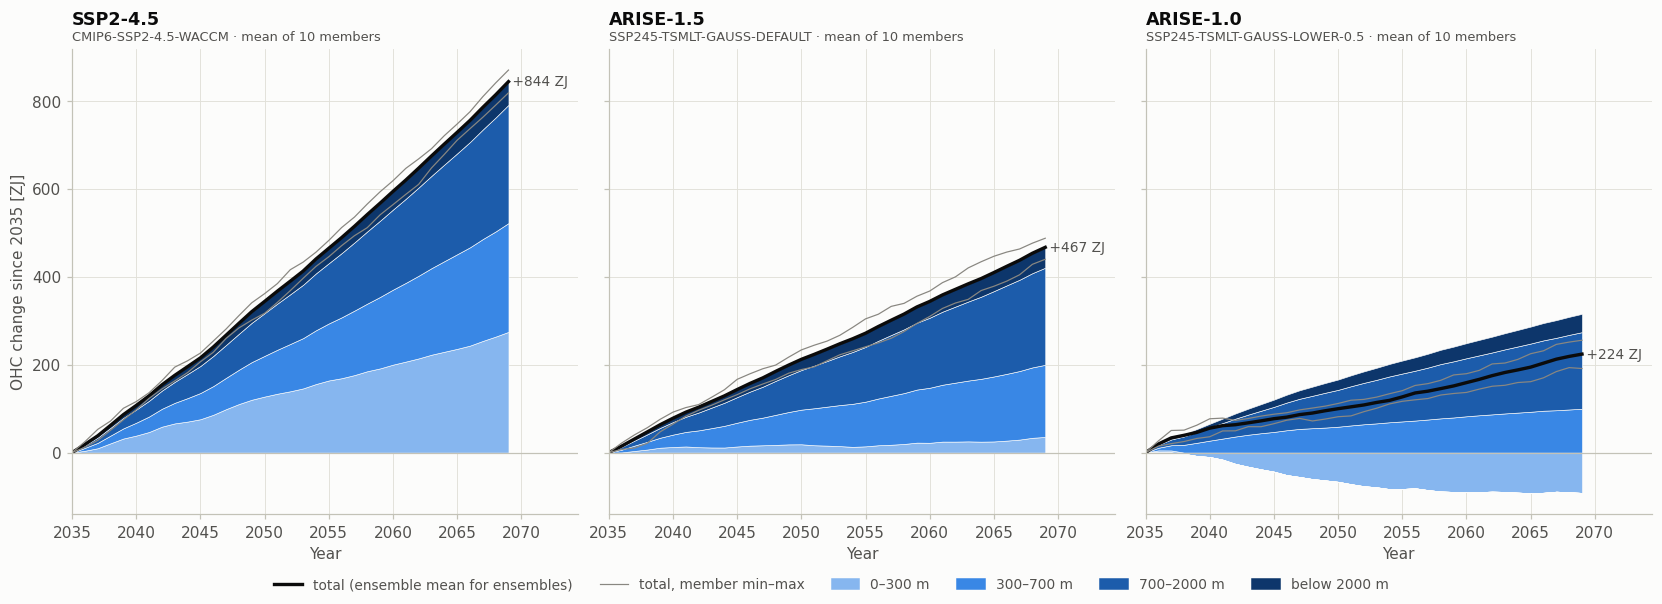

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5.4), sharex=True, sharey=True, layout="constrained")
oc.plot_layer_grid(fig, axes, [(name, data[name]["key"], data[name]["ohc"]) for name in ARISE_CONDITIONS], START, END)
plt.show()

## 2. Surface warming vs. ocean heat uptake: SSP2-4.5, ARISE-1.5 and ARISE-1.0

Each condition's ensemble-mean surface-temperature change (y) against its ocean heat uptake (x). The large point is
the change from the 2035–2039 mean to the 2065–2069 mean; the small points are the means over each 10-year window,
measured from the same 2035–2039 mean and joined in time order, so each line traces the condition's path.

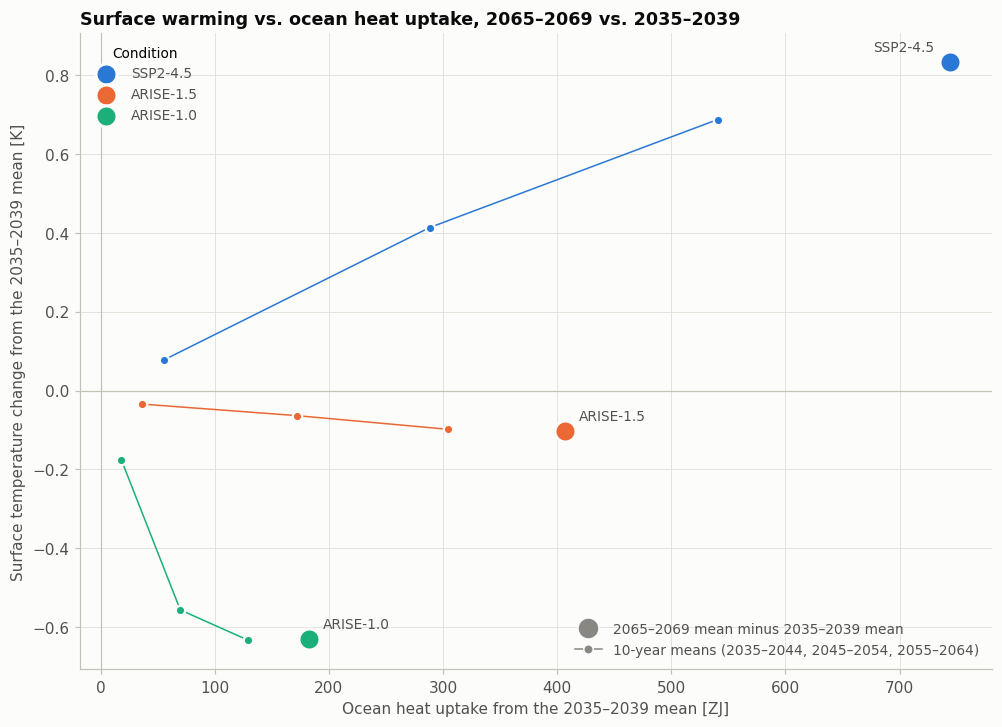

,members,ocean_heat_uptake_ZJ,surface_temperature_change_K,uptake_ZJ_2035-2044,uptake_ZJ_2045-2054,uptake_ZJ_2055-2064,dTS_K_2035-2044,dTS_K_2045-2054,dTS_K_2055-2064
condition,,,,,,,,,
SSP2-4.5,10,+744.48,+0.83,+55.67,+288.17,+540.53,+0.08,+0.41,+0.69
ARISE-1.5,10,+407.04,-0.10,+36.24,+171.96,+304.76,-0.03,-0.06,-0.10
ARISE-1.0,10,+182.99,-0.63,+18.19,+69.78,+129.40,-0.18,-0.56,-0.63


In [4]:
fig, ax = plt.subplots(figsize=(9, 6.5), layout="constrained")
arise_summary = oc.plot_uptake_vs_warming(
    ax, [(name, data[name]["ohc"].sel(ohc_depth=-1), data[name]["ts"]) for name in ARISE_CONDITIONS], START, END, WINDOW, styles=CONDITION_STYLES, base=BASE, final=FINAL)
ax.set_title(f"Surface warming vs. ocean heat uptake, {FINAL[0]}–{FINAL[1]} vs. {BASE[0]}–{BASE[1]}")
plt.show()
display(arise_summary.style.format("{:+.2f}", subset=[c for c in arise_summary if c != "members"]))

### 2b. The same, with each ensemble member

Figure 2 with every ensemble member added as small faded points (not joined): each member's own 2065–2069 minus
2035–2039 change (circle) and its own 10-year window means, measured from its own 2035–2039 mean. Shape marks the
period, for the ensemble means and their members alike: ▲ 2035–2044, ■ 2045–2054, ◆ 2055–2064; the faded cloud
around each ensemble-mean point is its members. The 10-year ensemble-mean points are half the area of the large
point. The table adds the member standard deviation of both quantities for each period.

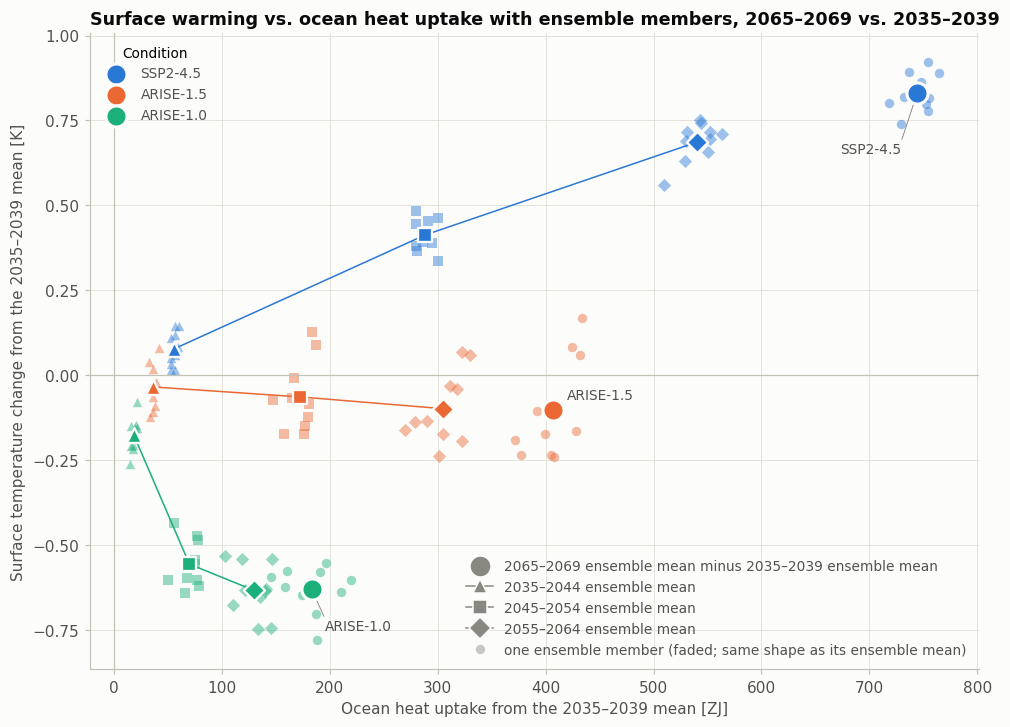

,members,ocean_heat_uptake_ZJ,surface_temperature_change_K,uptake_ZJ_member_sd,dTS_K_member_sd,uptake_ZJ_member_sd_2035-2044,dTS_K_member_sd_2035-2044,uptake_ZJ_member_sd_2045-2054,dTS_K_member_sd_2045-2054,uptake_ZJ_member_sd_2055-2064,dTS_K_member_sd_2055-2064,uptake_ZJ_2035-2044,uptake_ZJ_2045-2054,uptake_ZJ_2055-2064,dTS_K_2035-2044,dTS_K_2045-2054,dTS_K_2055-2064
condition,,,,,,,,,,,,,,,,,
SSP2-4.5,10,+744.48,+0.83,+14.62,+0.06,+2.69,+0.05,+8.12,+0.05,+15.75,+0.06,+55.67,+288.17,+540.53,+0.08,+0.41,+0.69
ARISE-1.5,10,+407.04,-0.10,+22.37,+0.15,+2.89,+0.07,+12.66,+0.10,+19.93,+0.11,+36.24,+171.96,+304.76,-0.03,-0.06,-0.10
ARISE-1.0,10,+182.99,-0.63,+23.54,+0.07,+2.27,+0.05,+10.15,+0.07,+15.25,+0.08,+18.19,+69.78,+129.40,-0.18,-0.56,-0.63


In [5]:
fig, ax = plt.subplots(figsize=(9, 6.5), layout="constrained")
arise_members = oc.plot_uptake_vs_warming(
    ax, [(name, data[name]["ohc"].sel(ohc_depth=-1), data[name]["ts"]) for name in ARISE_CONDITIONS], START, END, WINDOW,
    styles=CONDITION_STYLES, members=True, window_size=95, window_markers=["^", "s", "D"],
    base=BASE, final=FINAL)
ax.set_title(f"Surface warming vs. ocean heat uptake with ensemble members, {FINAL[0]}–{FINAL[1]} vs. {BASE[0]}–{BASE[1]}")
plt.show()
display(arise_members.style.format("{:+.2f}", subset=[c for c in arise_members if c != "members"]))

### 2c. Year-by-year paths: SSP2-4.5, ARISE-1.5 and ARISE-1.0

One panel per condition, on shared axes. Unlike figures 2 and 2b, both quantities here are the annual change since
the 2035 annual mean (the time-series convention). Points are the ensemble mean for each year, colored by year;
thin gray lines are the individual members' annual paths, showing the internal variability around the mean.

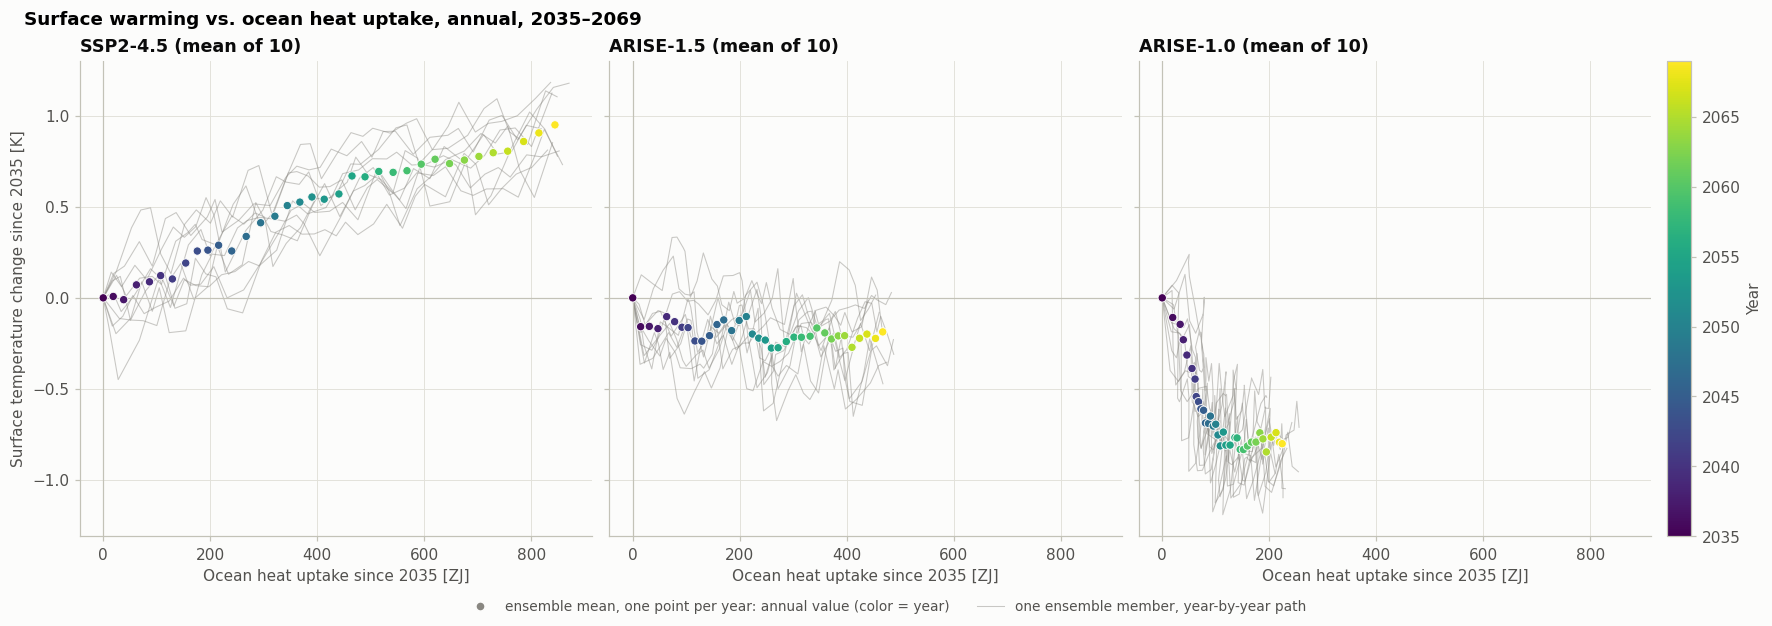

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.6), sharex=True, sharey=True, layout="constrained")
oc.plot_annual_paths(fig, axes, [(name, data[name]["ohc"].sel(ohc_depth=-1), data[name]["ts"])
                                 for name in ARISE_CONDITIONS], START, END)
fig.suptitle(f"Surface warming vs. ocean heat uptake, annual, {START}–{END}", x=0.01, ha="left", fontweight="bold")
plt.show()

### 2d. Year-by-year rates: SSP2-4.5, ARISE-1.5 and ARISE-1.0

Figure 2c as rates. Each year's rate is the least-squares slope over the five years centered on it (year − 2 to
year + 2), for ocean heat content (x, ZJ/yr) and surface temperature (y, K/decade). The first and last two years
(2035–2036, 2068–2069) have no full window and are left out, so points run 2037–2067; colors use the same year
scale as figure 2c. Gray lines are each member's own rates; the points are the ensemble mean (identical to the
mean of the member rates, since the slope is linear in the data).

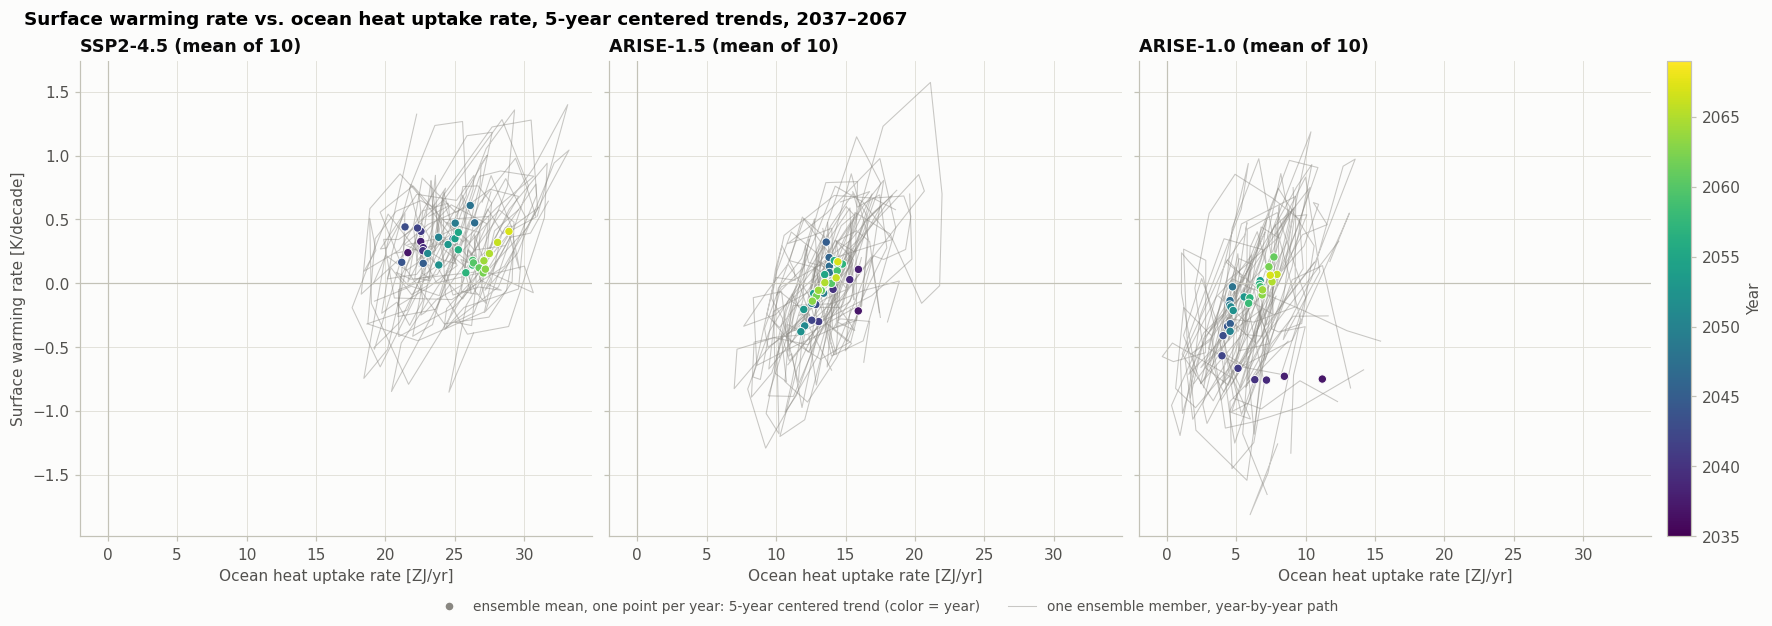

In [7]:
RATE_WINDOW = 5   # years in each centered least-squares trend
fig, axes = plt.subplots(1, 3, figsize=(16, 5.6), sharex=True, sharey=True, layout="constrained")
oc.plot_annual_paths(fig, axes, [(name, data[name]["ohc"].sel(ohc_depth=-1), data[name]["ts"])
                                 for name in ARISE_CONDITIONS], START, END, rate_window=RATE_WINDOW)
half = RATE_WINDOW // 2
fig.suptitle(f"Surface warming rate vs. ocean heat uptake rate, {RATE_WINDOW}-year centered trends, "
             f"{START + half}–{END - half}", x=0.01, ha="left", fontweight="bold")
plt.show()

## 3. Ocean heat uptake by depth layer: MCB conditions

The same as figure 1 for every MCB condition. The four CMIP6-compset MCB runs and their baseline are single runs;
"MCB 50% ensemble (smbb)" is the 10-member `MCB-050PCT` ensemble. The baseline starts in 2015 and is re-referenced
to 2035 like the others.

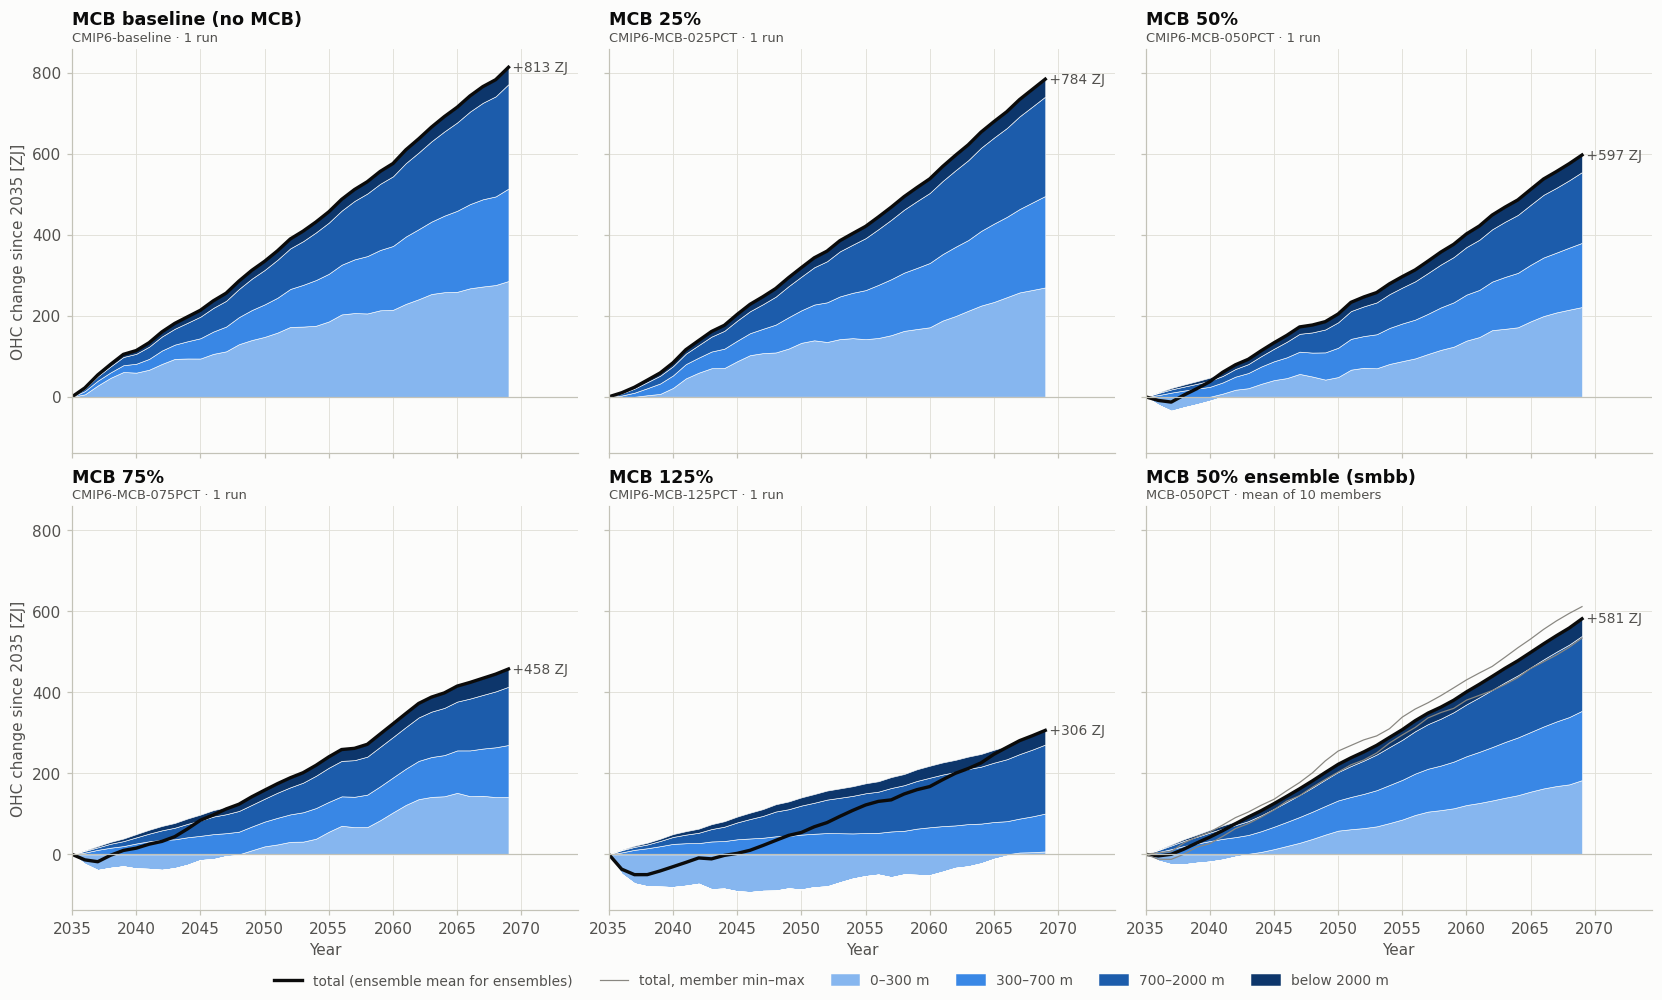

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=True, sharey=True, layout="constrained")
oc.plot_layer_grid(fig, axes, [(name, data[name]["key"], data[name]["ohc"]) for name in MCB_CONDITIONS], START, END)
plt.show()

## 4. Surface warming vs. ocean heat uptake: MCB conditions

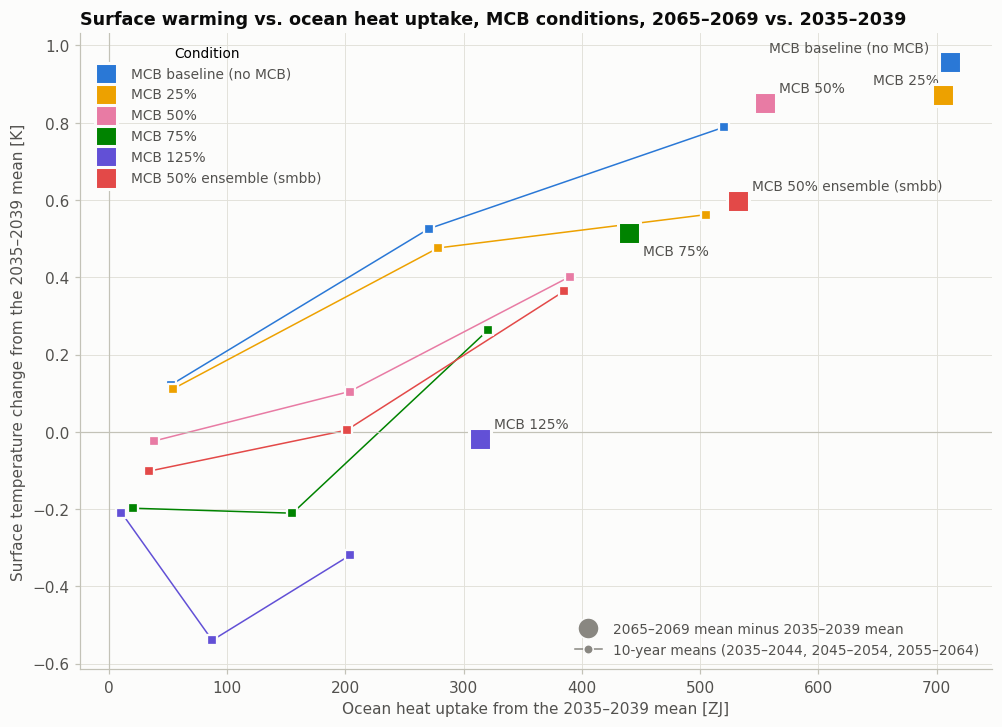

,members,ocean_heat_uptake_ZJ,surface_temperature_change_K,uptake_ZJ_2035-2044,uptake_ZJ_2045-2054,uptake_ZJ_2055-2064,dTS_K_2035-2044,dTS_K_2045-2054,dTS_K_2055-2064
condition,,,,,,,,,
MCB baseline (no MCB),1,+711.61,+0.96,+52.56,+270.67,+519.97,+0.12,+0.53,+0.79
MCB 25%,1,+705.12,+0.87,+54.31,+278.23,+505.29,+0.11,+0.48,+0.56
MCB 50%,1,+554.94,+0.85,+38.03,+203.48,+389.92,-0.02,+0.10,+0.40
MCB 75%,1,+440.18,+0.51,+20.35,+155.13,+320.70,-0.20,-0.21,+0.26
MCB 125%,1,+313.63,-0.02,+10.47,+87.34,+204.01,-0.21,-0.54,-0.32
MCB 50% ensemble (smbb),10,+531.96,+0.60,+33.86,+200.92,+385.12,-0.10,+0.00,+0.36


In [9]:
fig, ax = plt.subplots(figsize=(9, 6.5), layout="constrained")
mcb_summary = oc.plot_uptake_vs_warming(
    ax, [(name, data[name]["ohc"].sel(ohc_depth=-1), data[name]["ts"]) for name in MCB_CONDITIONS], START, END, WINDOW, styles=CONDITION_STYLES, base=BASE, final=FINAL)
ax.set_title(f"Surface warming vs. ocean heat uptake, MCB conditions, {FINAL[0]}–{FINAL[1]} vs. {BASE[0]}–{BASE[1]}")
plt.show()
display(mcb_summary.style.format("{:+.2f}", subset=[c for c in mcb_summary if c != "members"]))

### 4c. Year-by-year paths: MCB conditions

Figure 2c for the MCB conditions: annual surface-temperature change vs. ocean heat uptake, both since the 2035
annual mean, on shared axes, with points colored by year. Only "MCB 50% ensemble (smbb)" has several members, so
it alone has gray member paths; the other panels are single runs, whose points are the run itself.

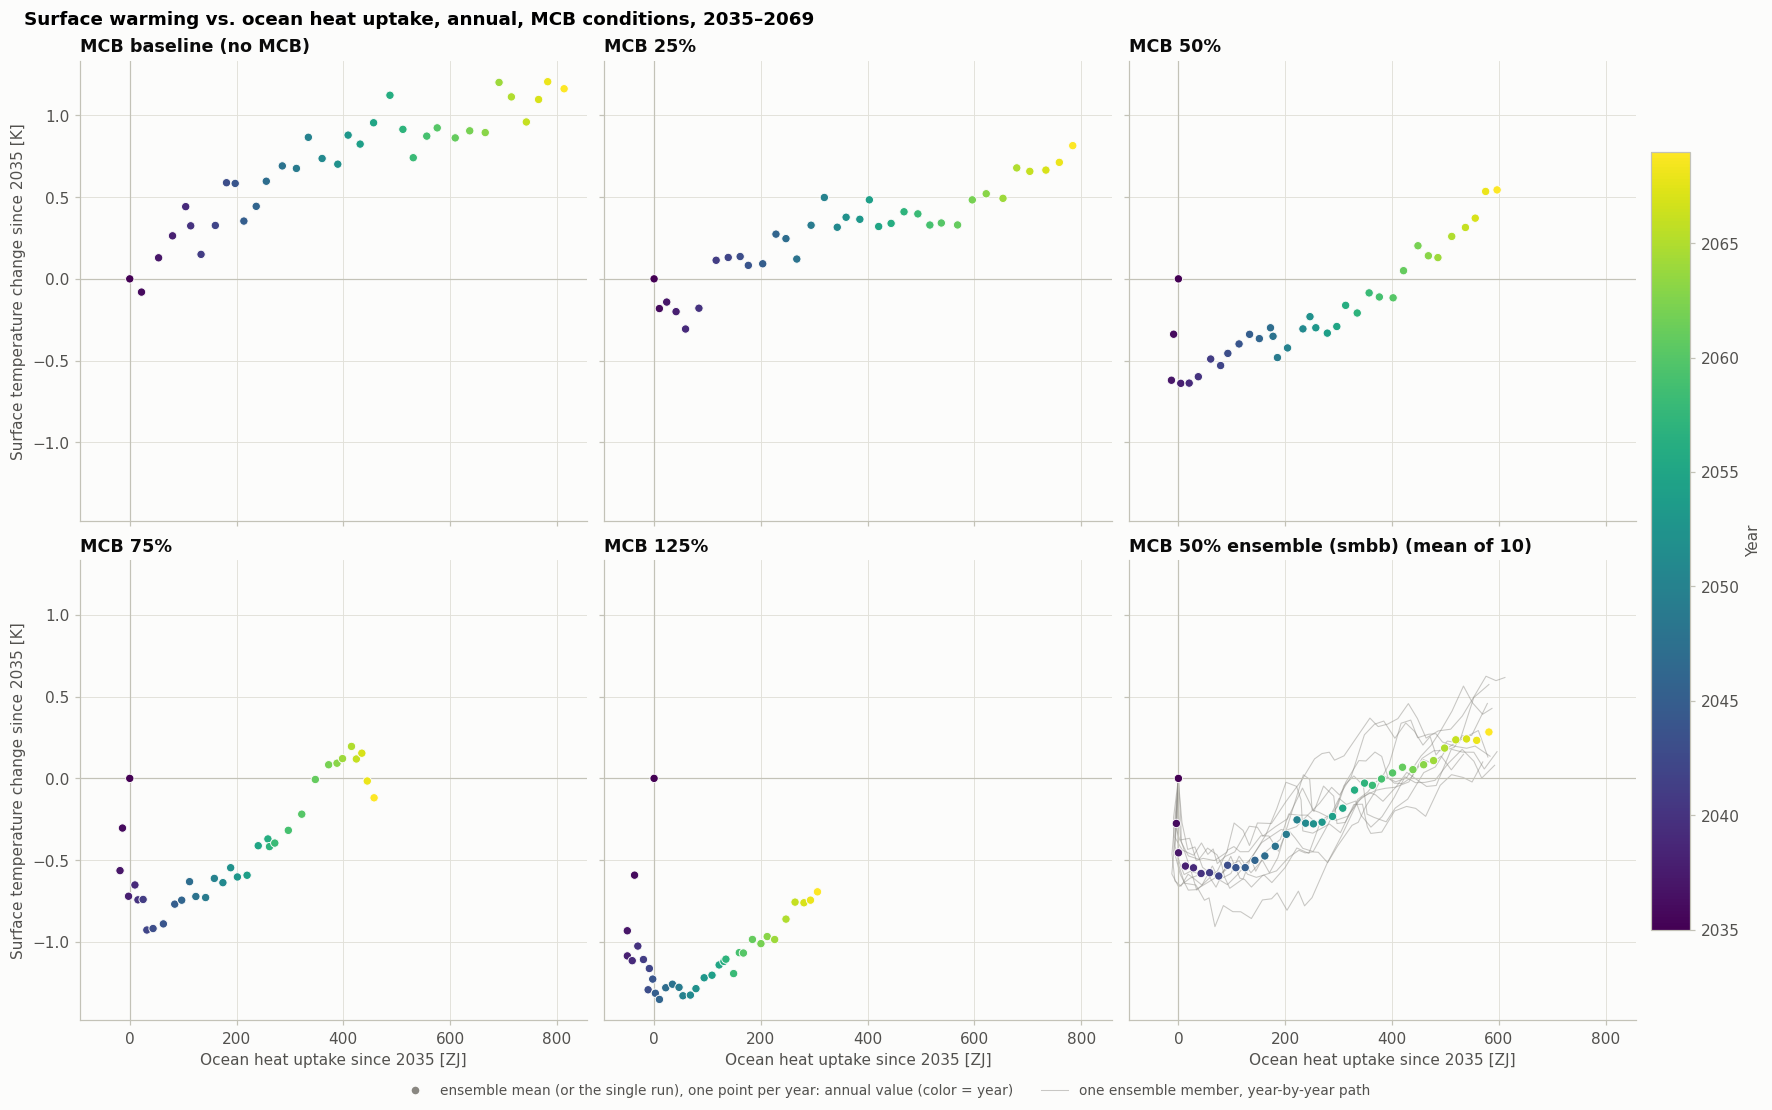

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10), sharex=True, sharey=True, layout="constrained")
oc.plot_annual_paths(fig, axes, [(name, data[name]["ohc"].sel(ohc_depth=-1), data[name]["ts"])
                                 for name in MCB_CONDITIONS], START, END)
fig.suptitle(f"Surface warming vs. ocean heat uptake, annual, MCB conditions, {START}–{END}", x=0.01, ha="left",
             fontweight="bold")
plt.show()

### 4d. Year-by-year rates: MCB conditions

Figure 2d for the MCB conditions: each year's 5-year centered least-squares trend in ocean heat content (ZJ/yr) and
surface temperature (K/decade), 2037–2067. For the single runs these trends carry the full year-to-year internal
variability, which the 10-member ensemble mean averages down.

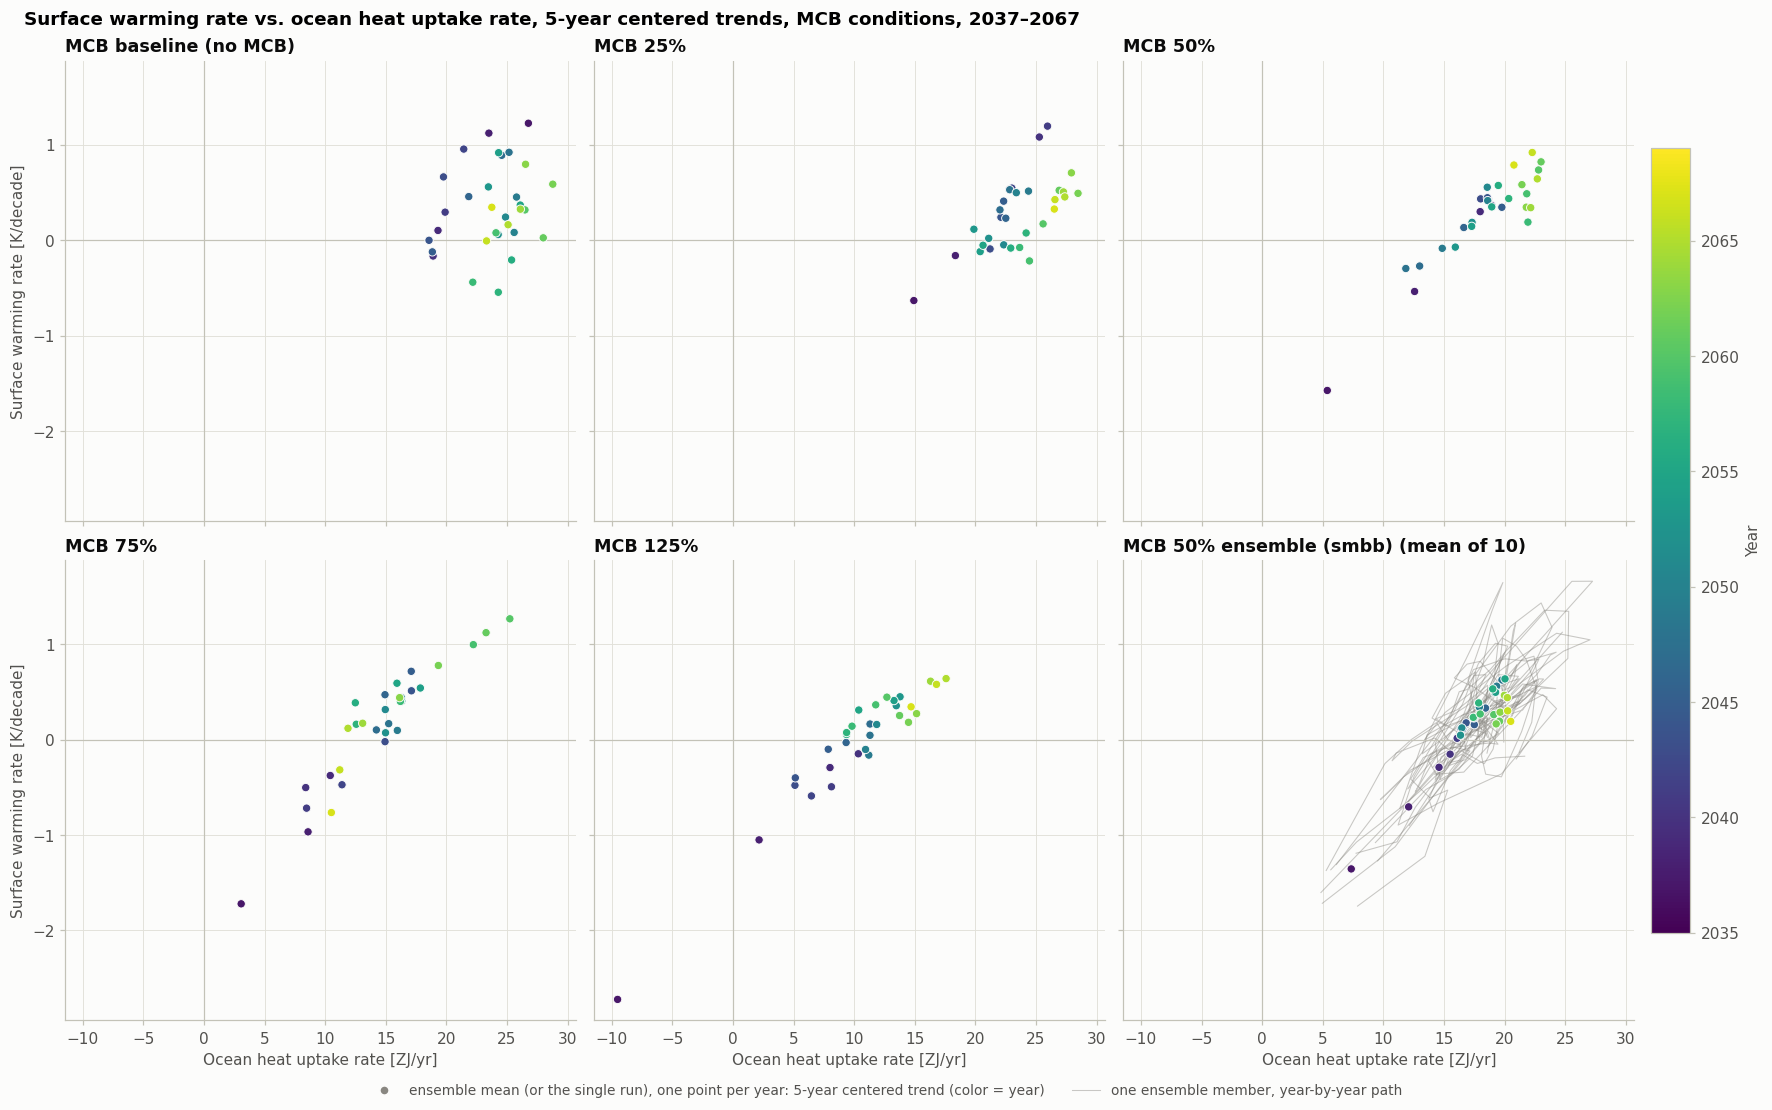

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10), sharex=True, sharey=True, layout="constrained")
oc.plot_annual_paths(fig, axes, [(name, data[name]["ohc"].sel(ohc_depth=-1), data[name]["ts"])
                                 for name in MCB_CONDITIONS], START, END, rate_window=RATE_WINDOW)
fig.suptitle(f"Surface warming rate vs. ocean heat uptake rate, {RATE_WINDOW}-year centered trends, MCB conditions, "
             f"{START + RATE_WINDOW // 2}–{END - RATE_WINDOW // 2}", x=0.01, ha="left", fontweight="bold")
plt.show()

**Notes on these choices.**
- *Two zero points.* The time series (figures 1, 3, 5) start each member at its 2035 annual mean. The scatter plots
  use the 2035–2039 mean instead, and the 2065–2069 mean as the end state, so a single year's internal variability
  (≈ ±0.1 K in surface temperature for the single-run MCB conditions) doesn't set the baseline or the end point.
  SAI and MCB both start in January 2035, so the first five years of response are inside the baseline.
- *10-year windows.* 2035–2044, 2045–2054 and 2055–2064, each measured from the 2035–2039 mean (so the first window
  sits near zero). The remaining 2065–2069 is shorter than a window and appears only as the end state. Change
  `WINDOW`, `BASE` or `FINAL` above to use other periods.
- *Ocean heat uptake* on the scatter plots is the OHC difference between the same periods as the surface-temperature
  change it is plotted against.

## 5. Total ocean heat uptake: all conditions

Ensemble-mean total (full-column) OHC change since 2035 for all nine conditions on one axes. Solid lines are CESM2-WACCM runs (SSP2-4.5 and ARISE), dashed lines CESM2 runs with CAM6 (the MCB family); the two no-intervention references share blue and differ by line style.

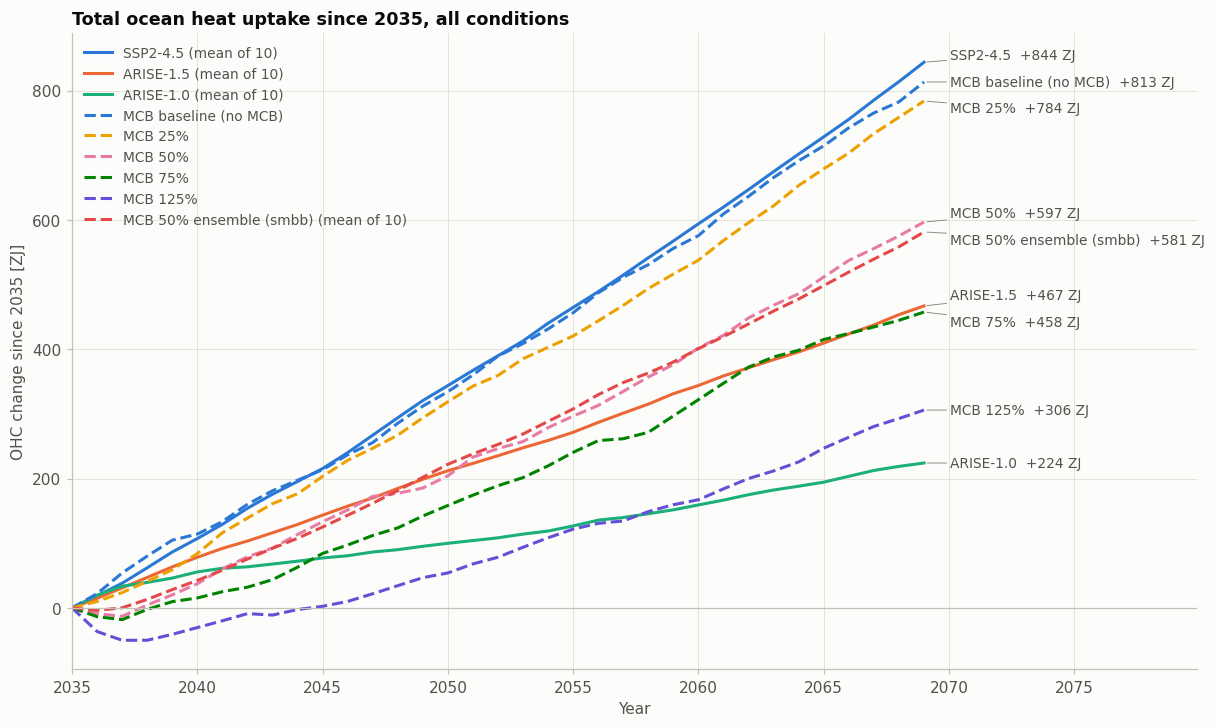

In [12]:
fig, ax = plt.subplots(figsize=(11, 6.5), layout="constrained")
oc.plot_total_comparison(ax, [(name, data[name]["ohc"].sel(ohc_depth=-1), CONDITION_STYLES[name])
                              for name in all_conditions], START, END)
ax.set_title(f"Total ocean heat uptake since {START}, all conditions")
ax.legend(loc="upper left", fontsize=9)
plt.show()

## 6. Surface warming vs. ocean heat uptake: all conditions, 2065–2069 vs. 2035–2039

One point per condition: its ensemble-mean change from the 2035–2039 mean to the 2065–2069 mean (the large points
of figures 2 and 4). Three ordinary least-squares fits of surface-temperature change on ocean heat uptake: the
thicker dashed line through all nine points, and a thinner dashed line through each model family alone
(CESM2-WACCM, circles; CESM2 with CAM6, squares). Each line is labeled with its r² and intercept; the legend adds its
slope.

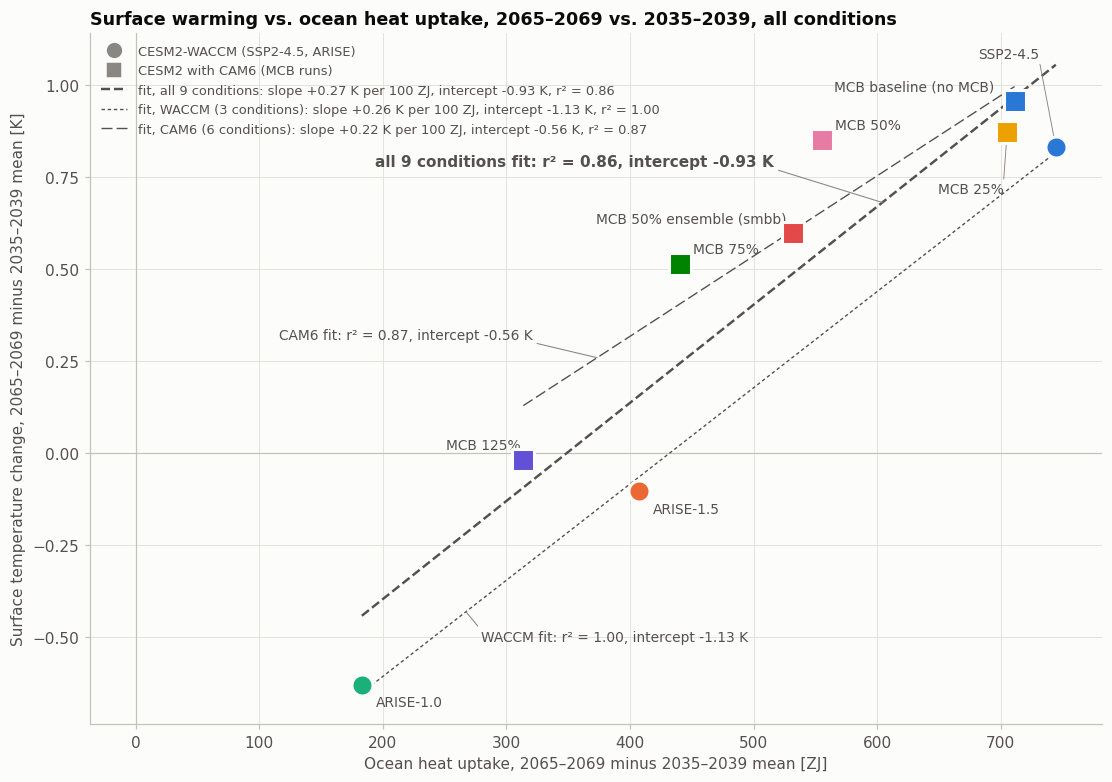

,n,slope_K_per_100ZJ,intercept_K,r2
all 9 conditions,9,+0.267,-0.931,0.861
WACCM (3 conditions),3,+0.262,-1.131,0.998
CAM6 (6 conditions),6,+0.218,-0.556,0.867


,members,ocean_heat_uptake_ZJ,surface_temperature_change_K
condition,,,
SSP2-4.5,10,+744.5,+0.83
ARISE-1.5,10,+407.0,-0.10
ARISE-1.0,10,+183.0,-0.63
MCB baseline (no MCB),1,+711.6,+0.96
MCB 25%,1,+705.1,+0.87
MCB 50%,1,+554.9,+0.85
MCB 75%,1,+440.2,+0.51
MCB 125%,1,+313.6,-0.02
MCB 50% ensemble (smbb),10,+532.0,+0.60


In [13]:
fig, ax = plt.subplots(figsize=(10, 7), layout="constrained")
points, fits = oc.plot_period_mean_regression(
    ax, [(name, data[name]["ohc"].sel(ohc_depth=-1), data[name]["ts"], CONDITION_STYLES[name])
         for name in all_conditions], START, END, family_markers=FAMILY_MARKERS, family_fits={"WACCM": "o", "CAM6": "s"},
    base=BASE, final=FINAL)
ax.set_title(f"Surface warming vs. ocean heat uptake, {FINAL[0]}–{FINAL[1]} vs. {BASE[0]}–{BASE[1]}, all conditions")
plt.show()
fits["slope_K_per_100ZJ"] = 100 * fits["slope_K_per_ZJ"]
display(fits[["n", "slope_K_per_100ZJ", "intercept_K", "r2"]].style.format(
    {"slope_K_per_100ZJ": "{:+.3f}", "intercept_K": "{:+.3f}", "r2": "{:.3f}"}))
display(points.style.format({"ocean_heat_uptake_ZJ": "{:+.1f}", "surface_temperature_change_K": "{:+.2f}"}))